### Iris Flower Classification Using Machine Learning
This project uses the Iris dataset to build a machine learning model that classifies iris flowers into three species: Iris-setosa, Iris-versicolor, and Iris-virginica. You will learn how to load the dataset, clean and preprocess data, visualize features, train a classification model, and evaluate its accuracy.

In [ ]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully.")

All libraries imported successfully.


Observation: These libraries provide the tools needed to perform the complete machine learning workflow.

In [3]:
#Load the dataset
df = pd.read_csv("Iris.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First five rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset shape:
(150, 6)

Column names:
['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']


Observation: The standard dataset contains 150 flower records and typically six columns, including an ID column.

In [4]:
#Explore the dataset
print("Dataset information:")
df.info()

print("\nStatistical summary:")
print(df.describe())

print("\nSpecies distribution:")
print(df["Species"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

Statistical summary:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.445368       0.828066      0.433594       1.764420      0.763161
min      1.000000       4.300000      2.000000       1.000000      0.100000
25%     38.250000       5.100000      2.800000       1.600000      0.30000

Observation: The classic Iris dataset has 50 samples for each of the three species, so the classes are balanced.

In [5]:
#Preprocess and clean the data
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove an unnecessary ID column if present
df = df.drop(columns=["Id"], errors="ignore")

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing target labels
df = df.dropna(subset=["Species"])

# Identify feature columns
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

# Convert features to numeric values
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing or invalid feature values
df = df.dropna(subset=features).reset_index(drop=True)

print("Missing values:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

Missing values:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Cleaned dataset shape: (147, 5)


Observation: The dataset is now ready for model training. The number of rows may decrease if duplicates or invalid records are found.

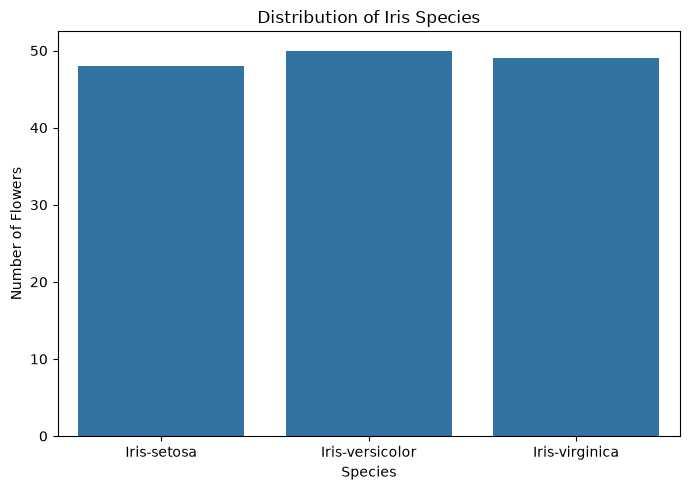

In [6]:
#Visualize the data
# 1- Species distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.tight_layout()
plt.show()

Observation: The chart shows how many examples belong to each flower species.

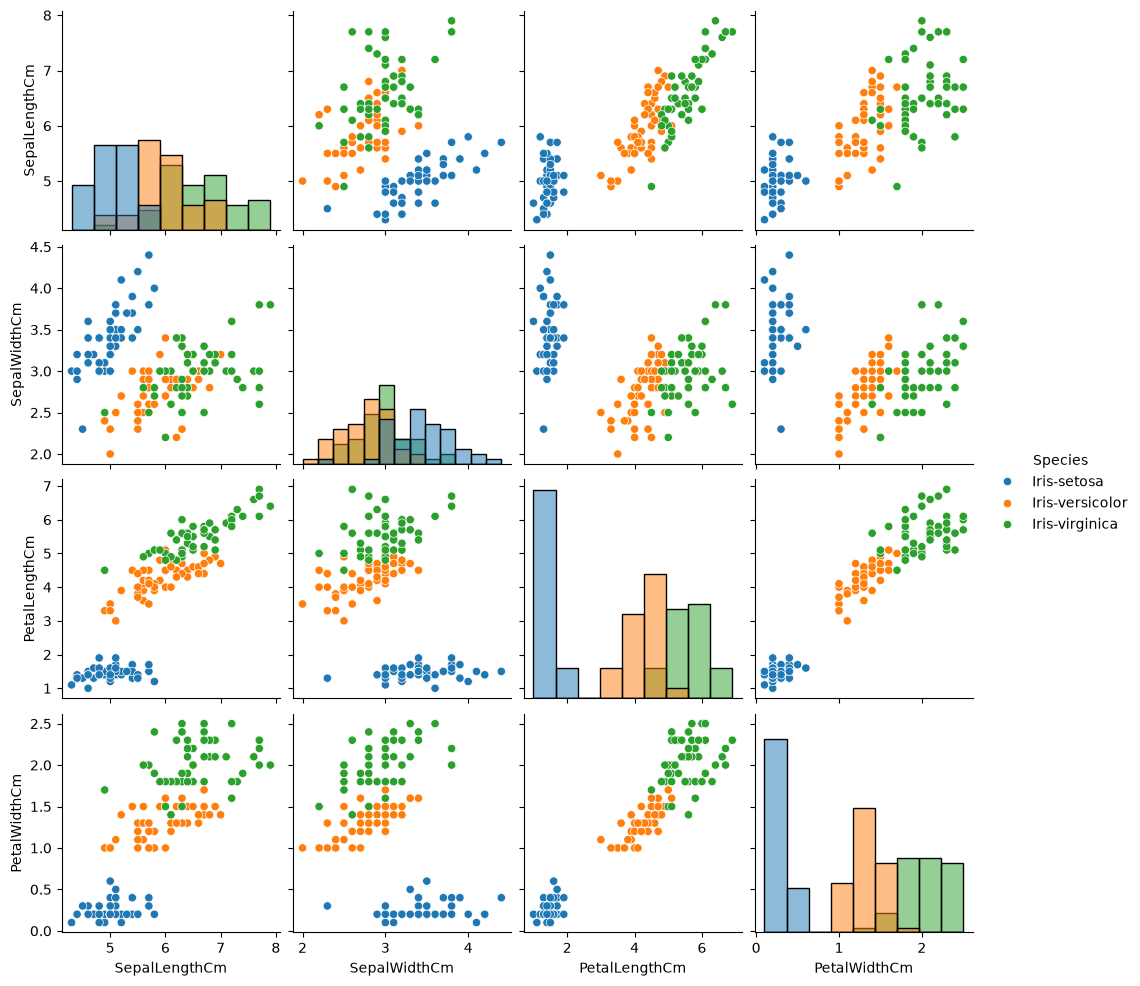

In [7]:
# 2- Feature relationship
sns.pairplot(
    df,
    vars=features,
    hue="Species",
    diag_kind="hist"
)

plt.show()

Observation: Petal length and petal width often separate the species more clearly than sepal measurements. Setosa is generally easier to distinguish, while Versicolor and Virginica can overlap.

In [8]:
#Separate input features and target
X = df[features]
y = df["Species"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (147, 4)
Target shape: (147,)


Observation: The model learns the relationship between measurements and species using X and y.

In [9]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 117
Testing samples: 30


Observation: If the cleaned dataset still has 150 rows, 120 samples will be used for training and 30 for testing.

In [10]:
#Train the machine learning model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


Observation: The model has learned patterns in the training examples that it can use to predict the species of unseen flowers.

In [11]:
#Evaluate model accuracy
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 96.67%

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



Observation: Random Forest often performs well on the classic Iris dataset, but the actual accuracy must be taken from your program's output. Do not assume a particular score before running the code.

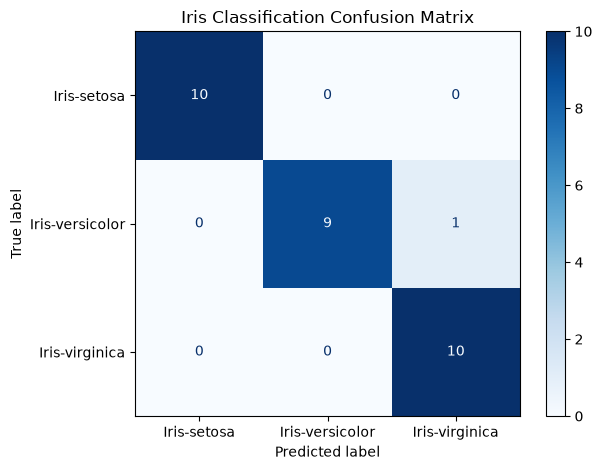

In [12]:
#Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Iris Classification Confusion Matrix")
plt.tight_layout()
plt.show()

Observation: Values on the main diagonal represent correct predictions. Values outside the diagonal represent misclassifications.

In [ ]:
#Predict the species of a new flowerS
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=features
)

prediction = model.predict(new_flower)

print("Predicted flower species:", prediction[0])

Predicted flower species: Iris-setosa


Observation: For these example measurements, the model will typically predict Iris-setosa or Iris-setosa's equivalent label in your CSV, such as Iris-setosa or Iris-setosa without punctuation differences. The exact label is determined by the dataset's target column.

         Feature  Importance
2  PetalLengthCm    0.443075
3   PetalWidthCm    0.414662
0  SepalLengthCm    0.121489
1   SepalWidthCm    0.020774


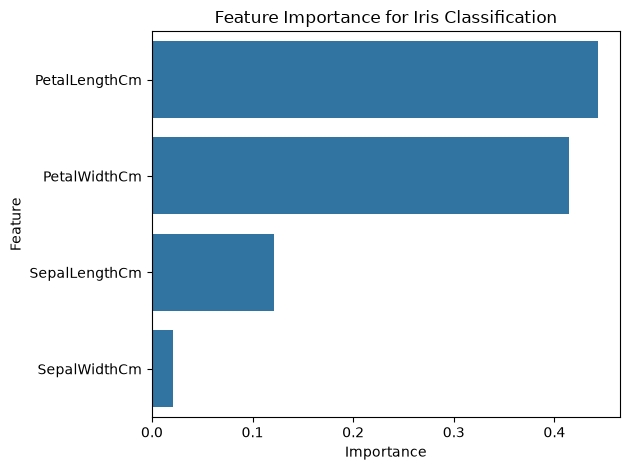

In [14]:
#Feature importance
importances = model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df)

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance for Iris Classification")
plt.tight_layout()
plt.show()

Observation: Petal measurements are often among the most important features. Importance values describe the fitted model's behavior, not causal effects.